In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../03_Cleaned_Data/kerala_tourism_master_dataset_25_destinations.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (25, 68)


,No,Destination,District,Latitude,Longitude,Attraction_Count,Hotels,Resorts,Homestays_Vacation_Rentals,Restaurants,...,Nearest_Airport,Airport_Distance,Local_or_Nearest_Bus_Hub,Major_Regional_Bus_Hub,Main_Road_or_Highway,Road_Accessibility,Transport_Notes,Nearest_Railway_Distance_km_numeric,Alternative_Railway_Distance_km_numeric,Nearest_Airport_Distance_km_numeric
0,1,Munnar,Idukki,10.089200,77.059700,9,245,161,450,214,...,Cochin International Airport,107 km,Munnar KSRTC Bus Stand,"KSRTC Bus Station, Ernakulam",NH 85 (Kochi–Dhanushkodi Road),"Paved roads; steep, winding ghat sections and ...",Distances and descriptions are transcribed fro...,68.2,108.0,107.0
1,2,Wayanad,Wayanad,11.685400,76.132000,17,184,267,580,412,...,Calicut International Airport,85–100 km to Kalpetta,Kalpetta New Bus Stand; KSRTC Sultan Bathery; ...,Kozhikode KSRTC Bus Stand,NH 766; Thamarassery Churam; Nedumpoil–Periya ...,Paved highways; ghat roads with 9 hairpin bend...,Distances and descriptions are transcribed fro...,110.0,90.0,100.0
2,3,Vagamon,Idukki,9.686181,76.905229,5,86,142,310,94,...,Cochin International Airport,94–110 km,Erattupetta Bus Stand,Kottayam KSRTC Bus Station,Kanjar–Pullikkanam Road; Pala–Erattupetta route,"Paved mountain roads; narrow turns, steep sect...",Distances and descriptions are transcribed fro...,65.0,40.0,110.0
3,4,Thekkady,Idukki,9.606325,77.169701,4,112,154,290,126,...,Madurai Airport,140 km,Kumily KSRTC Bus Stand,Kumily KSRTC Bus Stand,NH 183 (Kottayam–Kumily Road),Accessible road; winding plantation curves; ha...,Distances and descriptions are transcribed fro...,114.0,70.0,140.0
4,5,Alappuzha,Alappuzha,9.498067,76.338848,4,142,118,460,274,...,Cochin International Airport,75–85 km,Alappuzha KSRTC Bus Stand,Alappuzha KSRTC Bus Stand,NH 66,Good road access; highway widening/constructio...,Distances and descriptions are transcribed fro...,3.5,NaN,85.0


In [2]:
required_columns = [
    "Destination",
    "District",
    "Hotels",
    "Resorts",
    "Homestays_Vacation_Rentals",
    "Restaurants",
    "Hotels_Average_Rating",
    "Resorts_Average_Rating",
    "Attraction_Count",
    "Nearest_Airport_Distance_km_numeric",
    "Cluster",
    "Cluster_Name"
]

df_business = df[required_columns].copy()

df_business.head(25)

KeyError: "['Cluster', 'Cluster_Name'] not in index"

In [3]:
for column in df.columns:
    print(column)

No
Destination
District
Latitude
Longitude
Attraction_Count
Hotels
Resorts
Homestays_Vacation_Rentals
Restaurants
Bakeries_Confectioneries
Cafes_Tea_Rooms
Hotels_Average_Rating
Resorts_Average_Rating
Homestays_Average_Rating
Restaurants_Average_Rating
Approximation_And_Category_Notes
Source
Missing_Category_Convention
Count_Convention
Collection_Date
Rating_Scale
Review_Counts
Business_Counts
Source_Reported_Count
Count_Matches_Entries
Notes
Domestic_Visitors_2022
Foreign_Visitors_2022
Total_Visitors_2022
Domestic_Status_2022
Foreign_Status_2022
Total_Status_2022
Visitor_Estimation_Note_2022
Visitor_Data_Type_2022
Visitor_Source_2022
Domestic_Visitors_2023
Foreign_Visitors_2023
Total_Visitors_2023
Domestic_Status_2023
Foreign_Status_2023
Total_Status_2023
Visitor_Estimation_Note_2023
Visitor_Data_Type_2023
Visitor_Source_2023
Domestic_Visitors_2024
Foreign_Visitors_2024
Total_Visitors_2024
Domestic_Status_2024
Foreign_Status_2024
Total_Status_2024
Visitor_Estimation_Note_2024
Visitor_D

In [4]:
required_columns = [
    "Destination",
    "District",
    "Hotels",
    "Resorts",
    "Homestays_Vacation_Rentals",
    "Restaurants",
    "Hotels_Average_Rating",
    "Resorts_Average_Rating",
    "Attraction_Count",
    "Nearest_Airport_Distance_km_numeric"
]

df_business = df[required_columns].copy()

df_business.head(25)

,Destination,District,Hotels,Resorts,Homestays_Vacation_Rentals,Restaurants,Hotels_Average_Rating,Resorts_Average_Rating,Attraction_Count,Nearest_Airport_Distance_km_numeric
0,Munnar,Idukki,245,161,450,214,4.2,4.4,9,107.0
1,Wayanad,Wayanad,184,267,580,412,4.1,4.5,17,100.0
2,Vagamon,Idukki,86,142,310,94,4.0,4.4,5,110.0
3,Thekkady,Idukki,112,154,290,126,4.2,4.5,4,140.0
4,Alappuzha,Alappuzha,142,118,460,274,4.1,4.4,4,85.0
5,Kumarakom,Kottayam,127,74,240,84,4.3,4.6,4,85.0
6,Varkala,Thiruvananthapuram,116,214,490,172,4.2,4.3,5,50.0
7,Kovalam,Thiruvananthapuram,138,184,390,162,4.0,4.4,4,15.0
8,Kochi City,Ernakulam,480,65,720,1240,4.2,4.5,5,35.0
9,Kozhikode City,Kozhikode,246,42,310,684,4.2,4.4,5,26.0


In [5]:
cluster_df = pd.read_csv(
    "../07_Machine_Learning/kerala_tourism_cluster_assignments.csv"
)

print("Cluster dataset shape:", cluster_df.shape)

cluster_df.head()

Cluster dataset shape: (25, 4)


,Destination,District,Cluster,Cluster_Name
0,Munnar,Idukki,2,Established Leisure and Resort Destinations
1,Wayanad,Wayanad,2,Established Leisure and Resort Destinations
2,Vagamon,Idukki,2,Established Leisure and Resort Destinations
3,Thekkady,Idukki,2,Established Leisure and Resort Destinations
4,Alappuzha,Alappuzha,2,Established Leisure and Resort Destinations


In [6]:
df_business = pd.merge(
    df_business,
    cluster_df[["Destination", "Cluster", "Cluster_Name"]],
    on="Destination",
    how="left"
)

print("Merged dataset shape:", df_business.shape)
print("Missing cluster values:", df_business["Cluster"].isna().sum())

df_business.head(25)

Merged dataset shape: (25, 12)
Missing cluster values: 0


,Destination,District,Hotels,Resorts,Homestays_Vacation_Rentals,Restaurants,Hotels_Average_Rating,Resorts_Average_Rating,Attraction_Count,Nearest_Airport_Distance_km_numeric,Cluster,Cluster_Name
0,Munnar,Idukki,245,161,450,214,4.2,4.4,9,107.0,2,Established Leisure and Resort Destinations
1,Wayanad,Wayanad,184,267,580,412,4.1,4.5,17,100.0,2,Established Leisure and Resort Destinations
2,Vagamon,Idukki,86,142,310,94,4.0,4.4,5,110.0,2,Established Leisure and Resort Destinations
3,Thekkady,Idukki,112,154,290,126,4.2,4.5,4,140.0,2,Established Leisure and Resort Destinations
4,Alappuzha,Alappuzha,142,118,460,274,4.1,4.4,4,85.0,2,Established Leisure and Resort Destinations
5,Kumarakom,Kottayam,127,74,240,84,4.3,4.6,4,85.0,2,Established Leisure and Resort Destinations
6,Varkala,Thiruvananthapuram,116,214,490,172,4.2,4.3,5,50.0,2,Established Leisure and Resort Destinations
7,Kovalam,Thiruvananthapuram,138,184,390,162,4.0,4.4,4,15.0,2,Established Leisure and Resort Destinations
8,Kochi City,Ernakulam,480,65,720,1240,4.2,4.5,5,35.0,0,Urban Tourism and Commercial Hubs
9,Kozhikode City,Kozhikode,246,42,310,684,4.2,4.4,5,26.0,0,Urban Tourism and Commercial Hubs


In [7]:
visitor_df = pd.read_csv(
    "../06_EDA_Analysis/visitor_growth_2022_2024.csv"
)

print("Visitor dataset shape:", visitor_df.shape)

visitor_df.head()

Visitor dataset shape: (25, 9)


,Destination,Visitors_2022,Status_2022,Visitors_2023,Status_2023,Visitors_2024,Status_2024,Growth_2022_2024,Data_Quality
0,Munnar,1079320,No estimation note,1707059,No estimation note,2258056,No estimation note,109.210985,No estimation notes
1,Kumarakom,292201,No estimation note,350609,No estimation note,484356,No estimation note,65.761240,No estimation notes
2,Parassinikkadavu,200611,Estimated,287919,Estimated,331609,Estimated,65.299510,Contains estimates
3,Varkala,379634,No estimation note,491767,No estimation note,618562,No estimation note,62.936407,No estimation notes
4,Guruvayur,1463838,No estimation note,1916018,Estimated,2360999,No estimation note,61.288271,Contains estimates


In [8]:
df_business = pd.merge(
    df_business,
    visitor_df[
        [
            "Destination",
            "Visitors_2022",
            "Visitors_2023",
            "Visitors_2024",
            "Growth_2022_2024",
            "Data_Quality"
        ]
    ],
    on="Destination",
    how="left"
)

print("Final dataset shape:", df_business.shape)
print("Missing visitor values:")
print(df_business["Visitors_2024"].isna().sum())

df_business.head(25)

Final dataset shape: (25, 17)
Missing visitor values:
0


,Destination,District,Hotels,Resorts,Homestays_Vacation_Rentals,Restaurants,Hotels_Average_Rating,Resorts_Average_Rating,Attraction_Count,Nearest_Airport_Distance_km_numeric,Cluster,Cluster_Name,Visitors_2022,Visitors_2023,Visitors_2024,Growth_2022_2024,Data_Quality
0,Munnar,Idukki,245,161,450,214,4.2,4.4,9,107.0,2,Established Leisure and Resort Destinations,1079320,1707059,2258056,109.210985,No estimation notes
1,Wayanad,Wayanad,184,267,580,412,4.1,4.5,17,100.0,2,Established Leisure and Resort Destinations,597947,677503,493458,-17.474626,Contains estimates
2,Vagamon,Idukki,86,142,310,94,4.0,4.4,5,110.0,2,Established Leisure and Resort Destinations,238067,303066,321841,35.189253,Contains estimates
3,Thekkady,Idukki,112,154,290,126,4.2,4.5,4,140.0,2,Established Leisure and Resort Destinations,581098,762197,738892,27.154456,No estimation notes
4,Alappuzha,Alappuzha,142,118,460,274,4.1,4.4,4,85.0,2,Established Leisure and Resort Destinations,635496,570348,497872,-21.656155,No estimation notes
5,Kumarakom,Kottayam,127,74,240,84,4.3,4.6,4,85.0,2,Established Leisure and Resort Destinations,292201,350609,484356,65.761240,No estimation notes
6,Varkala,Thiruvananthapuram,116,214,490,172,4.2,4.3,5,50.0,2,Established Leisure and Resort Destinations,379634,491767,618562,62.936407,No estimation notes
7,Kovalam,Thiruvananthapuram,138,184,390,162,4.0,4.4,4,15.0,2,Established Leisure and Resort Destinations,521707,656380,686714,31.628289,No estimation notes
8,Kochi City,Ernakulam,480,65,720,1240,4.2,4.5,5,35.0,0,Urban Tourism and Commercial Hubs,2757936,3279635,3346571,21.343316,No estimation notes
9,Kozhikode City,Kozhikode,246,42,310,684,4.2,4.4,5,26.0,0,Urban Tourism and Commercial Hubs,864120,983445,956606,10.702912,No estimation notes


In [9]:
print("Dataset shape:", df_business.shape)

print("\nMissing values:")
print(df_business.isnull().sum())

print("\nDuplicate destinations:")
print(df_business["Destination"].duplicated().sum())

Dataset shape: (25, 17)

Missing values:
Destination                            0
District                               0
Hotels                                 0
Resorts                                0
Homestays_Vacation_Rentals             0
Restaurants                            0
Hotels_Average_Rating                  0
Resorts_Average_Rating                 0
Attraction_Count                       0
Nearest_Airport_Distance_km_numeric    0
Cluster                                0
Cluster_Name                           0
Visitors_2022                          0
Visitors_2023                          0
Visitors_2024                          0
Growth_2022_2024                       0
Data_Quality                           0
dtype: int64

Duplicate destinations:
0


In [10]:
business_columns = [
    "Hotels",
    "Resorts",
    "Homestays_Vacation_Rentals",
    "Restaurants"
]

business_averages = df_business[business_columns].mean()

print("Average business infrastructure across destinations:")
print(business_averages.round(2))

Average business infrastructure across destinations:
Hotels                        106.92
Resorts                        66.80
Homestays_Vacation_Rentals    212.48
Restaurants                   201.16
dtype: float64


In [11]:
for column in business_columns:
    average = df_business[column].mean()
    gap_column = column + "_Gap"
    df_business[gap_column] = average - df_business[column]

df_business[
    [
        "Destination",
        "Hotels_Gap",
        "Resorts_Gap",
        "Homestays_Vacation_Rentals_Gap",
        "Restaurants_Gap"
    ]
].head(25)

,Destination,Hotels_Gap,Resorts_Gap,Homestays_Vacation_Rentals_Gap,Restaurants_Gap
0,Munnar,-138.08,-94.2,-237.52,-12.84
1,Wayanad,-77.08,-200.2,-367.52,-210.84
2,Vagamon,20.92,-75.2,-97.52,107.16
3,Thekkady,-5.08,-87.2,-77.52,75.16
4,Alappuzha,-35.08,-51.2,-247.52,-72.84
5,Kumarakom,-20.08,-7.2,-27.52,117.16
6,Varkala,-9.08,-147.2,-277.52,29.16
7,Kovalam,-31.08,-117.2,-177.52,39.16
8,Kochi City,-373.08,1.8,-507.52,-1038.84
9,Kozhikode City,-139.08,24.8,-97.52,-482.84


In [12]:
gap_columns = [
    "Hotels_Gap",
    "Resorts_Gap",
    "Homestays_Vacation_Rentals_Gap",
    "Restaurants_Gap"
]

df_business["Overall_Gap_Score"] = (
    df_business[gap_columns].mean(axis=1)
)

opportunity_ranking = df_business[
    ["Destination", "Cluster_Name", "Growth_2022_2024",
     "Data_Quality", "Overall_Gap_Score"]
].sort_values(
    by="Overall_Gap_Score",
    ascending=False
)

opportunity_ranking

,Destination,Cluster_Name,Growth_2022_2024,Data_Quality,Overall_Gap_Score
22,Ranipuram,Developing and Nature-Based Destinations,20.741871,Contains estimates,133.09
16,Ponmudi,Developing and Nature-Based Destinations,10.889609,Contains estimates,127.09
23,Palaruvi,Developing and Nature-Based Destinations,10.889609,Contains estimates,127.09
24,Meenkunnu–Payyambalam,Developing and Nature-Based Destinations,-11.525890,Contains estimates,126.34
19,Nelliyampathy,Developing and Nature-Based Destinations,18.953062,Contains estimates,124.59
21,Thalassery,Developing and Nature-Based Destinations,16.911727,Contains estimates,121.84
20,Silent Valley,Developing and Nature-Based Destinations,21.810924,Contains estimates,117.34
17,Thenmala,Developing and Nature-Based Destinations,17.810723,Contains estimates,117.09
18,Konni,Developing and Nature-Based Destinations,17.633968,Contains estimates,114.84
14,Malampuzha,Developing and Nature-Based Destinations,42.022427,Contains estimates,103.59


In [13]:
def classify_opportunity(row):

    if row["Overall_Gap_Score"] > 0 and row["Growth_2022_2024"] > 0:
        return "High Gap + Positive Growth"

    elif row["Overall_Gap_Score"] > 0 and row["Growth_2022_2024"] <= 0:
        return "High Gap + Negative Growth"

    elif row["Overall_Gap_Score"] <= 0 and row["Growth_2022_2024"] > 0:
        return "Low Gap + Positive Growth"

    else:
        return "Low Gap + Negative Growth"


df_business["Opportunity_Category"] = df_business.apply(
    classify_opportunity,
    axis=1
)

df_business[
    [
        "Destination",
        "Overall_Gap_Score",
        "Growth_2022_2024",
        "Data_Quality",
        "Opportunity_Category"
    ]
].sort_values(
    by="Overall_Gap_Score",
    ascending=False
)

,Destination,Overall_Gap_Score,Growth_2022_2024,Data_Quality,Opportunity_Category
22,Ranipuram,133.09,20.741871,Contains estimates,High Gap + Positive Growth
16,Ponmudi,127.09,10.889609,Contains estimates,High Gap + Positive Growth
23,Palaruvi,127.09,10.889609,Contains estimates,High Gap + Positive Growth
24,Meenkunnu–Payyambalam,126.34,-11.525890,Contains estimates,High Gap + Negative Growth
19,Nelliyampathy,124.59,18.953062,Contains estimates,High Gap + Positive Growth
21,Thalassery,121.84,16.911727,Contains estimates,High Gap + Positive Growth
20,Silent Valley,117.34,21.810924,Contains estimates,High Gap + Positive Growth
17,Thenmala,117.09,17.810723,Contains estimates,High Gap + Positive Growth
18,Konni,114.84,17.633968,Contains estimates,High Gap + Positive Growth
14,Malampuzha,103.59,42.022427,Contains estimates,High Gap + Positive Growth


In [14]:
df_business.to_csv(
    "../08_Results/profitability_opportunity_analysis.csv",
    index=False
)

print("Business opportunity analysis saved successfully!")

Business opportunity analysis saved successfully!


In [15]:
def calculate_profitability(investment, monthly_revenue, monthly_expenses):

    monthly_profit = monthly_revenue - monthly_expenses

    annual_profit = monthly_profit * 12

    if monthly_profit > 0:
        payback_period = investment / monthly_profit
    else:
        payback_period = None

    annual_roi = (annual_profit / investment) * 100

    return {
        "Monthly Profit": monthly_profit,
        "Annual Profit": annual_profit,
        "Payback Period (Months)": payback_period,
        "Annual ROI (%)": annual_roi
    }

In [16]:
result = calculate_profitability(
    investment=1000000,
    monthly_revenue=200000,
    monthly_expenses=120000
)

for key, value in result.items():
    print(key, ":", value)

Monthly Profit : 80000
Annual Profit : 960000
Payback Period (Months) : 12.5
Annual ROI (%) : 96.0


In [17]:
def get_destination_details(destination):

    result = df_business[
        df_business["Destination"] == destination
    ]

    if result.empty:
        print("Destination not found!")
        return

    details = result.iloc[0]

    print("Destination:", details["Destination"])
    print("District:", details["District"])
    print("Tourism Cluster:", details["Cluster_Name"])
    print("Hotels:", details["Hotels"])
    print("Resorts:", details["Resorts"])
    print("Homestays:", details["Homestays_Vacation_Rentals"])
    print("Restaurants:", details["Restaurants"])
    print("Visitor Growth:", round(details["Growth_2022_2024"], 2), "%")
    print("Opportunity:", details["Opportunity_Category"])
    print("Visitor Data Quality:", details["Data_Quality"])

In [18]:
def tourism_business_estimator(
    destination,
    business_type,
    investment,
    monthly_revenue,
    monthly_expenses
):

    get_destination_details(destination)

    print("\nBUSINESS PROFITABILITY ANALYSIS")

    print("Business Type:", business_type)

    result = calculate_profitability(
        investment,
        monthly_revenue,
        monthly_expenses
    )

    print("\nEstimated Results")

    for key, value in result.items():

        if value is None:
            print(key, ": Cannot be calculated")

        elif "Months" in key:
            print(key, ":", round(value, 2))

        elif "ROI" in key:
            print(key, ":", round(value, 2), "%")

        else:
            print(key, ": ₹", f"{value:,.2f}")

In [19]:
tourism_business_estimator(
    destination="Kumarakom",
    business_type="Resort",
    investment=10000000,
    monthly_revenue=500000,
    monthly_expenses=300000
)

Destination: Kumarakom
District: Kottayam
Tourism Cluster: Established Leisure and Resort Destinations
Hotels: 127
Resorts: 74
Homestays: 240
Restaurants: 84
Visitor Growth: 65.76 %
Opportunity: High Gap + Positive Growth
Visitor Data Quality: No estimation notes

BUSINESS PROFITABILITY ANALYSIS
Business Type: Resort

Estimated Results
Monthly Profit : ₹ 200,000.00
Annual Profit : ₹ 2,400,000.00
Payback Period (Months) : 50.0
Annual ROI (%) : 24.0 %


In [20]:
test_result = {
    "Destination": "Kumarakom",
    "Business_Type": "Resort",
    "Initial_Investment": 10000000,
    "Monthly_Revenue": 500000,
    "Monthly_Expenses": 300000,
    **result
}

profitability_df = pd.DataFrame([test_result])

profitability_df.to_csv(
    "../08_Results/profitability_estimator_test.csv",
    index=False
)

print("Profitability test results saved successfully!")

Profitability test results saved successfully!


In [21]:
import importlib.util

if importlib.util.find_spec("ipywidgets"):
    print("ipywidgets is already installed!")
else:
    print("ipywidgets is not installed.")

ipywidgets is already installed!


In [22]:
import importlib.util

if importlib.util.find_spec("ipywidgets"):
    print("ipywidgets is already installed!")
else:
    print("ipywidgets is not installed.")

ipywidgets is already installed!


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

destination_dropdown = widgets.Dropdown(
    options=sorted(df_business["Destination"].unique()),
    description="Destination:",
    layout=widgets.Layout(width="400px")
)

business_dropdown = widgets.Dropdown(
    options=["Hotel", "Resort", "Homestay", "Restaurant"],
    description="Business:",
    layout=widgets.Layout(width="400px")
)

investment_input = widgets.FloatText(
    value=1000000,
    description="Investment ₹:",
    layout=widgets.Layout(width="400px")
)

revenue_input = widgets.FloatText(
    value=200000,
    description="Revenue ₹:",
    layout=widgets.Layout(width="400px")
)

expenses_input = widgets.FloatText(
    value=120000,
    description="Expenses ₹:",
    layout=widgets.Layout(width="400px")
)

calculate_button = widgets.Button(
    description="Calculate Profitability",
    button_style="success"
)

output = widgets.Output()

def calculate_button_clicked(button):
    with output:
        clear_output()

        if investment_input.value <= 0:
            print("Investment must be greater than zero.")
            return

        if revenue_input.value < 0 or expenses_input.value < 0:
            print("Revenue and expenses cannot be negative.")
            return

        tourism_business_estimator(
            destination=destination_dropdown.value,
            business_type=business_dropdown.value,
            investment=investment_input.value,
            monthly_revenue=revenue_input.value,
            monthly_expenses=expenses_input.value
        )

calculate_button.on_click(calculate_button_clicked)

display(
    destination_dropdown,
    business_dropdown,
    investment_input,
    revenue_input,
    expenses_input,
    calculate_button,
    output
)

Dropdown(description='Destination:', layout=Layout(width='400px'), options=('Alappuzha', 'Athirappilly', 'Beka…

Dropdown(description='Business:', layout=Layout(width='400px'), options=('Hotel', 'Resort', 'Homestay', 'Resta…

FloatText(value=1000000.0, description='Investment ₹:', layout=Layout(width='400px'))

FloatText(value=200000.0, description='Revenue ₹:', layout=Layout(width='400px'))

FloatText(value=120000.0, description='Expenses ₹:', layout=Layout(width='400px'))

Button(button_style='success', description='Calculate Profitability', style=ButtonStyle())

Output()

In [24]:
def recommend_business(destination):

    selected = df_business[
        df_business["Destination"] == destination
    ]

    if selected.empty:
        print("Destination not found!")
        return

    row = selected.iloc[0]

    business_gaps = {
        "Hotel": row["Hotels_Gap"],
        "Resort": row["Resorts_Gap"],
        "Homestay": row["Homestays_Vacation_Rentals_Gap"],
        "Restaurant": row["Restaurants_Gap"]
    }

    recommendations = sorted(
        business_gaps.items(),
        key=lambda x: x[1],
        reverse=True
    )

    print("BUSINESS RECOMMENDATIONS")
    print("------------------------")
    print("Destination:", destination)
    print("Visitor Growth:", round(row["Growth_2022_2024"], 2), "%")
    print("Opportunity:", row["Opportunity_Category"])
    print("Data Quality:", row["Data_Quality"])

    print("\nRecommended business categories:")

    for business, gap in recommendations:

        if gap > 0:
            print(business, "- Positive infrastructure gap:", round(gap, 2))
        else:
            print(business, "- Below overall infrastructure gap:", round(gap, 2))

In [25]:
recommend_business("Kumarakom")

BUSINESS RECOMMENDATIONS
------------------------
Destination: Kumarakom
Visitor Growth: 65.76 %
Opportunity: High Gap + Positive Growth
Data Quality: No estimation notes

Recommended business categories:
Restaurant - Positive infrastructure gap: 117.16
Resort - Below overall infrastructure gap: -7.2
Hotel - Below overall infrastructure gap: -20.08
Homestay - Below overall infrastructure gap: -27.52


In [26]:
recommendation_results = []

for index, row in df_business.iterrows():

    business_gaps = {
        "Hotel": row["Hotels_Gap"],
        "Resort": row["Resorts_Gap"],
        "Homestay": row["Homestays_Vacation_Rentals_Gap"],
        "Restaurant": row["Restaurants_Gap"]
    }

    best_business = max(
        business_gaps,
        key=business_gaps.get
    )

    recommendation_results.append({
        "Destination": row["Destination"],
        "Visitor_Growth": row["Growth_2022_2024"],
        "Opportunity_Category": row["Opportunity_Category"],
        "Recommended_Business": best_business,
        "Infrastructure_Gap": business_gaps[best_business],
        "Data_Quality": row["Data_Quality"]
    })

recommendation_df = pd.DataFrame(recommendation_results)

recommendation_df = recommendation_df.sort_values(
    by="Infrastructure_Gap",
    ascending=False
)

recommendation_df

,Destination,Visitor_Growth,Opportunity_Category,Recommended_Business,Infrastructure_Gap,Data_Quality
21,Thalassery,16.911727,High Gap + Positive Growth,Homestay,212.48,Contains estimates
23,Palaruvi,10.889609,High Gap + Positive Growth,Homestay,212.48,Contains estimates
20,Silent Valley,21.810924,High Gap + Positive Growth,Homestay,212.48,Contains estimates
24,Meenkunnu–Payyambalam,-11.525890,High Gap + Negative Growth,Homestay,197.48,Contains estimates
16,Ponmudi,10.889609,High Gap + Positive Growth,Restaurant,187.16,Contains estimates
22,Ranipuram,20.741871,High Gap + Positive Growth,Restaurant,186.16,Contains estimates
19,Nelliyampathy,18.953062,High Gap + Positive Growth,Restaurant,179.16,Contains estimates
17,Thenmala,17.810723,High Gap + Positive Growth,Homestay,177.48,Contains estimates
18,Konni,17.633968,High Gap + Positive Growth,Homestay,172.48,Contains estimates
14,Malampuzha,42.022427,High Gap + Positive Growth,Homestay,167.48,Contains estimates


In [27]:
def get_best_recommendation(row):

    business_gaps = {
        "Hotel": row["Hotels_Gap"],
        "Resort": row["Resorts_Gap"],
        "Homestay": row["Homestays_Vacation_Rentals_Gap"],
        "Restaurant": row["Restaurants_Gap"]
    }

    best_business = max(business_gaps, key=business_gaps.get)
    best_gap = business_gaps[best_business]

    if best_gap > 0:
        return pd.Series([best_business, best_gap])

    else:
        return pd.Series(["No clear infrastructure gap", best_gap])


recommendation_df[
    ["Recommended_Business", "Infrastructure_Gap"]
] = df_business.apply(get_best_recommendation, axis=1)

recommendation_df

,Destination,Visitor_Growth,Opportunity_Category,Recommended_Business,Infrastructure_Gap,Data_Quality
21,Thalassery,16.911727,High Gap + Positive Growth,Homestay,212.48,Contains estimates
23,Palaruvi,10.889609,High Gap + Positive Growth,Homestay,212.48,Contains estimates
20,Silent Valley,21.810924,High Gap + Positive Growth,Homestay,212.48,Contains estimates
24,Meenkunnu–Payyambalam,-11.525890,High Gap + Negative Growth,Homestay,197.48,Contains estimates
16,Ponmudi,10.889609,High Gap + Positive Growth,Restaurant,187.16,Contains estimates
22,Ranipuram,20.741871,High Gap + Positive Growth,Restaurant,186.16,Contains estimates
19,Nelliyampathy,18.953062,High Gap + Positive Growth,Restaurant,179.16,Contains estimates
17,Thenmala,17.810723,High Gap + Positive Growth,Homestay,177.48,Contains estimates
18,Konni,17.633968,High Gap + Positive Growth,Homestay,172.48,Contains estimates
14,Malampuzha,42.022427,High Gap + Positive Growth,Homestay,167.48,Contains estimates


In [28]:
recommendation_df.to_csv(
    "../08_Results/final_profitability_recommendations.csv",
    index=False
)

print("Final business recommendations saved successfully!")

print("\nTotal destinations:", len(recommendation_df))

print("\nRecommended business types:")
print(recommendation_df["Recommended_Business"].value_counts())

Final business recommendations saved successfully!

Total destinations: 25

Recommended business types:
Recommended_Business
Restaurant                     10
Homestay                        9
Resort                          3
No clear infrastructure gap     3
Name: count, dtype: int64


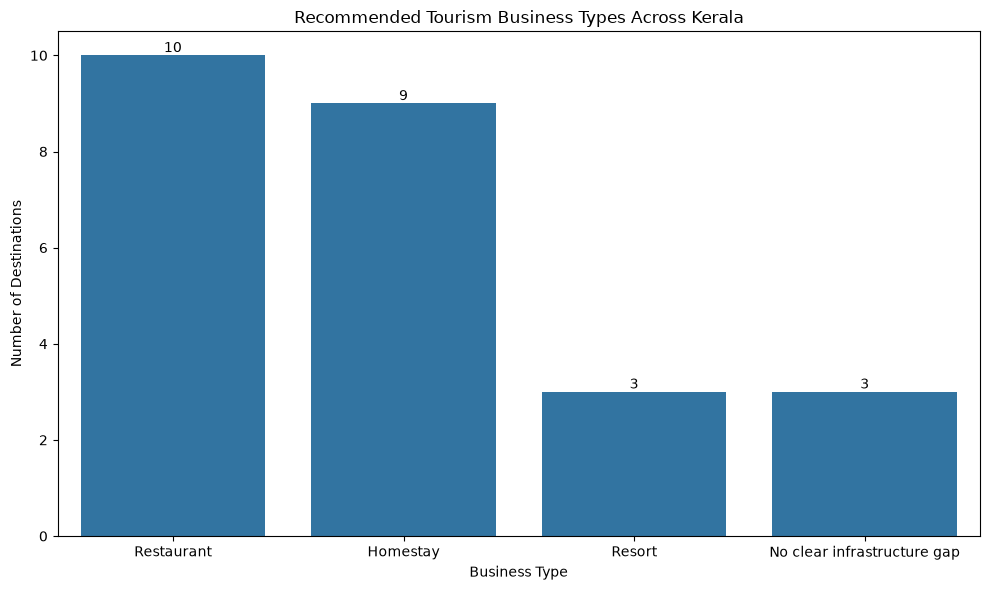

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

recommendation_counts = recommendation_df[
    "Recommended_Business"
].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=recommendation_counts.index,
    y=recommendation_counts.values
)

plt.title("Recommended Tourism Business Types Across Kerala")
plt.xlabel("Business Type")
plt.ylabel("Number of Destinations")

for i, value in enumerate(recommendation_counts.values):
    plt.text(i, value, str(value), ha="center", va="bottom")

plt.tight_layout()

plt.savefig(
    "../09_Visualizations/recommended_business_types.png",
    dpi=300
)

plt.show()

In [30]:
def compare_destinations(destination1, destination2):

    data1 = df_business[
        df_business["Destination"] == destination1
    ].iloc[0]

    data2 = df_business[
        df_business["Destination"] == destination2
    ].iloc[0]

    comparison = pd.DataFrame({
        destination1: data1[
            [
                "Hotels",
                "Resorts",
                "Homestays_Vacation_Rentals",
                "Restaurants",
                "Attraction_Count",
                "Growth_2022_2024",
                "Overall_Gap_Score"
            ]
        ],
        destination2: data2[
            [
                "Hotels",
                "Resorts",
                "Homestays_Vacation_Rentals",
                "Restaurants",
                "Attraction_Count",
                "Growth_2022_2024",
                "Overall_Gap_Score"
            ]
        ]
    })

    return comparison

In [31]:
compare_destinations("Kumarakom", "Munnar")

,Kumarakom,Munnar
Hotels,127,245
Resorts,74,161
Homestays_Vacation_Rentals,240,450
Restaurants,84,214
Attraction_Count,4,9
Growth_2022_2024,65.76124,109.210985
Overall_Gap_Score,15.59,-120.66


In [32]:
destination1 = widgets.Dropdown(
    options=sorted(df_business["Destination"].unique()),
    description="Destination 1:"
)

destination2 = widgets.Dropdown(
    options=sorted(df_business["Destination"].unique()),
    value="Munnar",
    description="Destination 2:"
)

compare_button = widgets.Button(
    description="Compare Destinations",
    button_style="success"
)

compare_output = widgets.Output()

def compare_button_clicked(button):

    with compare_output:
        clear_output()

        if destination1.value == destination2.value:
            print("Please select two different destinations.")
            return

        display(
            compare_destinations(
                destination1.value,
                destination2.value
            )
        )

compare_button.on_click(compare_button_clicked)

display(
    destination1,
    destination2,
    compare_button,
    compare_output
)

Dropdown(description='Destination 1:', options=('Alappuzha', 'Athirappilly', 'Bekal', 'Guruvayur', 'Kochi City…

Dropdown(description='Destination 2:', index=11, options=('Alappuzha', 'Athirappilly', 'Bekal', 'Guruvayur', '…

Button(button_style='success', description='Compare Destinations', style=ButtonStyle())

Output()

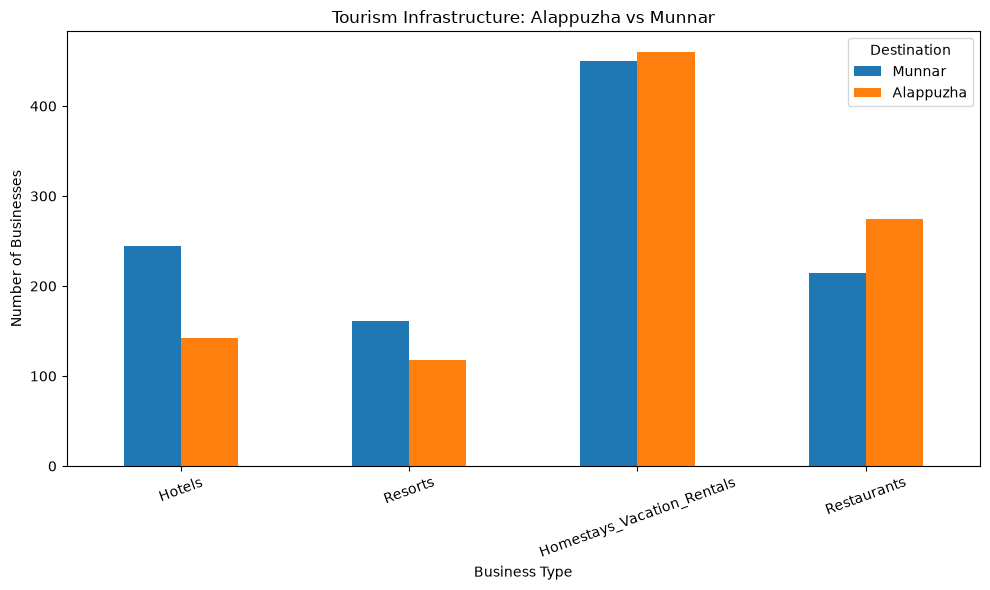

In [33]:
def plot_destination_comparison(destination1, destination2):

    columns = [
        "Hotels",
        "Resorts",
        "Homestays_Vacation_Rentals",
        "Restaurants"
    ]

    data = df_business[
        df_business["Destination"].isin(
            [destination1, destination2]
        )
    ].set_index("Destination")[columns]

    data.T.plot(kind="bar", figsize=(10, 6))

    plt.title(
        f"Tourism Infrastructure: {destination1} vs {destination2}"
    )
    plt.xlabel("Business Type")
    plt.ylabel("Number of Businesses")
    plt.xticks(rotation=20)
    plt.legend(title="Destination")
    plt.tight_layout()
    plt.show()


plot_destination_comparison("Alappuzha", "Munnar")

In [34]:
def plot_destination_comparison(destination1, destination2):

    columns = [
        "Hotels",
        "Resorts",
        "Homestays_Vacation_Rentals",
        "Restaurants"
    ]

    data = df_business[
        df_business["Destination"].isin([destination1, destination2])
    ].set_index("Destination")

    data = data.loc[[destination1, destination2], columns]

    data.columns = [
        "Hotels",
        "Resorts",
        "Homestays",
        "Restaurants"
    ]

    ax = data.T.plot(kind="bar", figsize=(10, 6))

    plt.title(f"Tourism Infrastructure: {destination1} vs {destination2}")
    plt.xlabel("Business Type")
    plt.ylabel("Number of Businesses")
    plt.xticks(rotation=0)
    plt.legend(title="Destination")
    plt.tight_layout()

    plt.savefig(
        "../09_Visualizations/destination_comparison.png",
        dpi=300
    )

    plt.show()

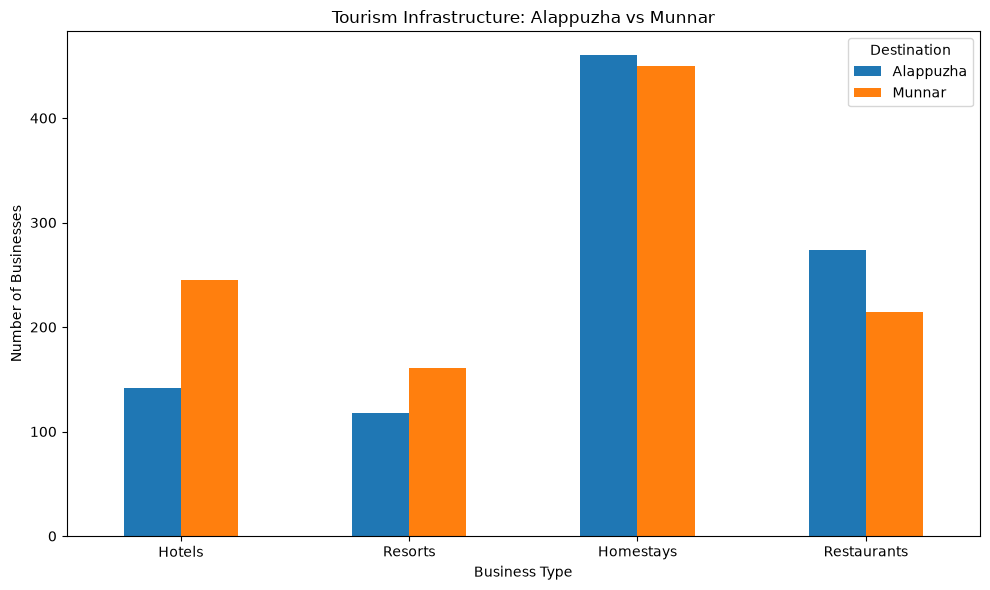

In [35]:
plot_destination_comparison("Alappuzha", "Munnar")